# Part III: Vanilla RNN palindrome prediction

## Task 1: model and training protocol

A palindrome has total length $T$. The model observes its first $T-1$ scalar digits and predicts the last digit among ten classes. Every batch starts with a zero hidden state. The time loop computes $h_t=\tanh(W_{hx}x_t+W_{hh}h_{t-1}+b_h)$, and the final output is $o=W_{ph}h_{T-1}+b_o$. Cross-entropy receives these logits directly.

The implementation uses RMSProp, learning rate 0.001, hidden size 128, batch size 128, and gradient clipping at global norm 10. Weights are initialized uniformly within $\pm1/\sqrt{H}$ and biases to zero. This initialization is an explicit implementation choice. Training-batch metrics are measured before their update; fixed-set evaluation metrics use the updated model.

Evaluation uses 1,000 fixed independent random draws by default. The finite palindrome space allows overlap with training, especially at short lengths. Accuracy describes prediction on the generating distribution. The notebook reads saved results by default.

The formal study uses seeds 42, 43 and 44 at the starter budget of 10,000 updates per model. Each seed changes initialization, online training samples and the fixed evaluation sample. Across-seed standard deviation therefore includes all three sources of variability. Every reported endpoint is the final update, even if an earlier checkpoint scored higher. The earlier 1,000-update pilot remains saved in its own study directory.

In [1]:
from pathlib import Path
import json
import sys
import numpy as np
import matplotlib.pyplot as plt
import torch
from IPython.display import display, Markdown

PART_DIR = Path.cwd().resolve()
if not (PART_DIR / "vanilla_rnn.py").exists():
    PART_DIR = PART_DIR / "Part 3"
if not (PART_DIR / "vanilla_rnn.py").exists():
    raise FileNotFoundError("Run from assignment2 or Part 3.")
sys.path.insert(0, str(PART_DIR))
from vanilla_rnn import VanillaRNN
from run_experiments import run_study

torch.set_num_threads(1)
RUN_STUDY = False
STUDY_PATH = PART_DIR / "results/rnn_length_study/study-0dz07fnj/summary.json"  # Frozen formal study.


In [2]:
with torch.random.fork_rng():
    torch.manual_seed(42)
    inspection_model = VanillaRNN(4, 1, 128, 10, 128)

rows = ["| Parameter | Shape | Elements |", "|---|---|---|"]
for name, parameter in inspection_model.named_parameters():
    rows.append(f"| {name} | {tuple(parameter.shape)} | {parameter.numel()} |")
display(Markdown("\n".join(rows)))
assert sum(p.numel() for p in inspection_model.parameters()) == 17930

shape_rows = [
    "| Operation for T=5 | Input | Output |",
    "|---|---|---|",
    "| Add feature dimension | (B, 4) | (B, 4, 1) |",
    "| Input projection at step t | (B, 1) | (B, 128) |",
    "| Recurrent projection | (B, 128) | (B, 128) |",
    "| Sum and tanh | (B, 128) | (B, 128) |",
    "| Final output projection | (B, 128) | (B, 10) |",
    "| Mean cross-entropy | logits (B, 10), labels (B,) | scalar |",
]
display(Markdown("\n".join(shape_rows)))
with torch.no_grad():
    assert inspection_model(torch.zeros(7, 4)).shape == (7, 10)
del inspection_model


| Parameter | Shape | Elements |
|---|---|---|
| input_to_hidden.weight | (128, 1) | 128 |
| input_to_hidden.bias | (128,) | 128 |
| hidden_to_hidden.weight | (128, 128) | 16384 |
| hidden_to_output.weight | (10, 128) | 1280 |
| hidden_to_output.bias | (10,) | 10 |

| Operation for T=5 | Input | Output |
|---|---|---|
| Add feature dimension | (B, 4) | (B, 4, 1) |
| Input projection at step t | (B, 1) | (B, 128) |
| Recurrent projection | (B, 128) | (B, 128) |
| Sum and tanh | (B, 128) | (B, 128) |
| Final output projection | (B, 128) | (B, 10) |
| Mean cross-entropy | logits (B, 10), labels (B,) | scalar |

The same recurrent parameters are reused at every time step. Autograd differentiates the entire unrolled computation. The update order is `zero_grad`, forward, cross-entropy, `backward`, `clip_grad_norm_`, then `optimizer.step`. Each gradient has the same shape as its parameter. The saved gradient norm is the total parameter-gradient norm before clipping for a recorded training batch.

## Task 2: accuracy versus total palindrome length

Each length gets a newly initialized model. The study fixes optimizer updates, batch size, hidden size, learning rate, and evaluation sample count across lengths. Longer sequences perform more recurrent operations per update. The default full study uses 10,000 updates per length. Enabling the following cell launches that computation.

In [3]:
if RUN_STUDY:
    study_dir = run_study(
        lengths=[5, 9, 13, 17, 21],
        seeds=[42, 43, 44],
        train_steps=10000,
        eval_freq=500,
        eval_samples=1000,
        device="cpu",
        output_dir=PART_DIR / "results" / "rnn_length_study",
    )
    STUDY_PATH = study_dir / "summary.json"


In [4]:
if STUDY_PATH is None:
    candidates = list((PART_DIR / "results" / "rnn_length_study").glob("*/summary.json"))
    if not candidates:
        raise FileNotFoundError("Run run_experiments.py or set STUDY_PATH to an existing summary.")
    summary_path = max(candidates, key=lambda path: path.stat().st_mtime)
else:
    summary_path = Path(STUDY_PATH).expanduser().resolve()
summary = json.loads(summary_path.read_text())
records = summary["records"]
if not records:
    raise ValueError("This study has not completed any individual runs yet.")
short_budget = summary["train_steps"] < 10000
scope = "Short-budget pilot" if short_budget else "Palindrome-length experiment"
print("Study:", summary_path)
print("Status:", summary["status"])
print("Updates per model:", summary["train_steps"])
print("Seeds:", summary["seeds"])
print("Completed runs:", len(records), "/", len(summary["planned_lengths"]) * len(summary["seeds"]))
if short_budget:
    display(Markdown("**This study uses fewer than the starter's 10,000 training updates per model. Its results describe that shorter budget.**"))

rows = ["| T | Seed | Updates | Evaluation samples | Final loss | Final accuracy |", "|---|---|---|---|---|---|"]
for record in sorted(records, key=lambda r: (r["palindrome_length"], r["seed"])):
    rows.append(f"| {record['palindrome_length']} | {record['seed']} | {record['train_steps']} | "
                f"{record['eval_samples']} | {record['final_eval_loss']:.4f} | {record['final_eval_accuracy']:.2%} |")
display(Markdown("\n".join(rows)))


Study: <assignment-root>/Part 3/results/rnn_length_study/study-0dz07fnj/summary.json
Status: complete
Updates per model: 10000
Seeds: [42, 43, 44]
Completed runs: 15 / 15


| T | Seed | Updates | Evaluation samples | Final loss | Final accuracy |
|---|---|---|---|---|---|
| 5 | 42 | 10000 | 1000 | 0.0002 | 100.00% |
| 5 | 43 | 10000 | 1000 | 0.0025 | 100.00% |
| 5 | 44 | 10000 | 1000 | 0.0046 | 100.00% |
| 9 | 42 | 10000 | 1000 | 0.0002 | 100.00% |
| 9 | 43 | 10000 | 1000 | 0.0007 | 100.00% |
| 9 | 44 | 10000 | 1000 | 0.0008 | 100.00% |
| 13 | 42 | 10000 | 1000 | 0.0000 | 100.00% |
| 13 | 43 | 10000 | 1000 | 1.1204 | 39.70% |
| 13 | 44 | 10000 | 1000 | 0.1513 | 88.40% |
| 17 | 42 | 10000 | 1000 | 1.6832 | 20.80% |
| 17 | 43 | 10000 | 1000 | 1.0428 | 52.70% |
| 17 | 44 | 10000 | 1000 | 1.6894 | 20.70% |
| 21 | 42 | 10000 | 1000 | 1.8707 | 18.70% |
| 21 | 43 | 10000 | 1000 | 1.8046 | 18.60% |
| 21 | 44 | 10000 | 1000 | 0.0033 | 100.00% |

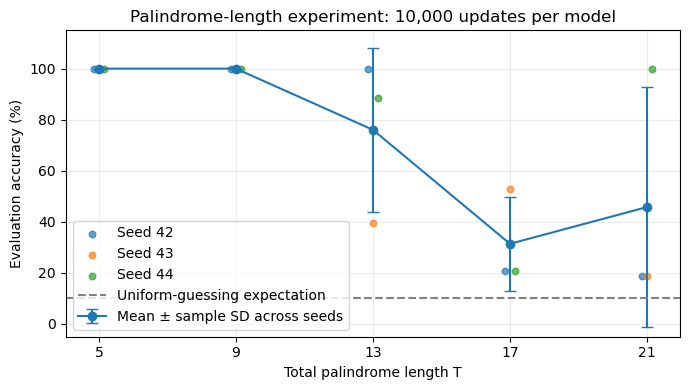

In [5]:
lengths = sorted({r["palindrome_length"] for r in records})
values = [[r["final_eval_accuracy"] for r in records if r["palindrome_length"] == length]
          for length in lengths]
means = 100 * np.array([np.mean(group) for group in values])
fig, axis = plt.subplots(figsize=(7, 4))
if all(len(group) > 1 for group in values):
    deviations = 100 * np.array([np.std(group, ddof=1) for group in values])
    axis.errorbar(lengths, means, yerr=deviations, marker="o", capsize=4,
                  label="Mean ± sample SD across seeds")
else:
    for seed in summary["seeds"]:
        selected = sorted((r for r in records if r["seed"] == seed), key=lambda r: r["palindrome_length"])
        if selected:
            axis.plot([r["palindrome_length"] for r in selected],
                      [100 * r["final_eval_accuracy"] for r in selected], marker="o", label=f"Seed {seed}")
for seed_index, seed in enumerate(summary['seeds']):
    selected = sorted((r for r in records if r['seed']==seed), key=lambda r:r['palindrome_length'])
    axis.scatter([r['palindrome_length']+(seed_index-1)*0.15 for r in selected],
                 [100*r['final_eval_accuracy'] for r in selected],s=22,alpha=0.7,label=f'Seed {seed}')
axis.axhline(10, color="gray", linestyle="--", label="Uniform-guessing expectation")
axis.set(xlabel="Total palindrome length T", ylabel="Evaluation accuracy (%)",
         title=f"{scope}: {summary['train_steps']:,} updates per model", ylim=(-5, 115))
axis.set_xticks(lengths)
axis.grid(alpha=0.25)
axis.legend()
fig.tight_layout()
fig.savefig(summary_path.parent / "accuracy_vs_length.png", dpi=180)
plt.show()


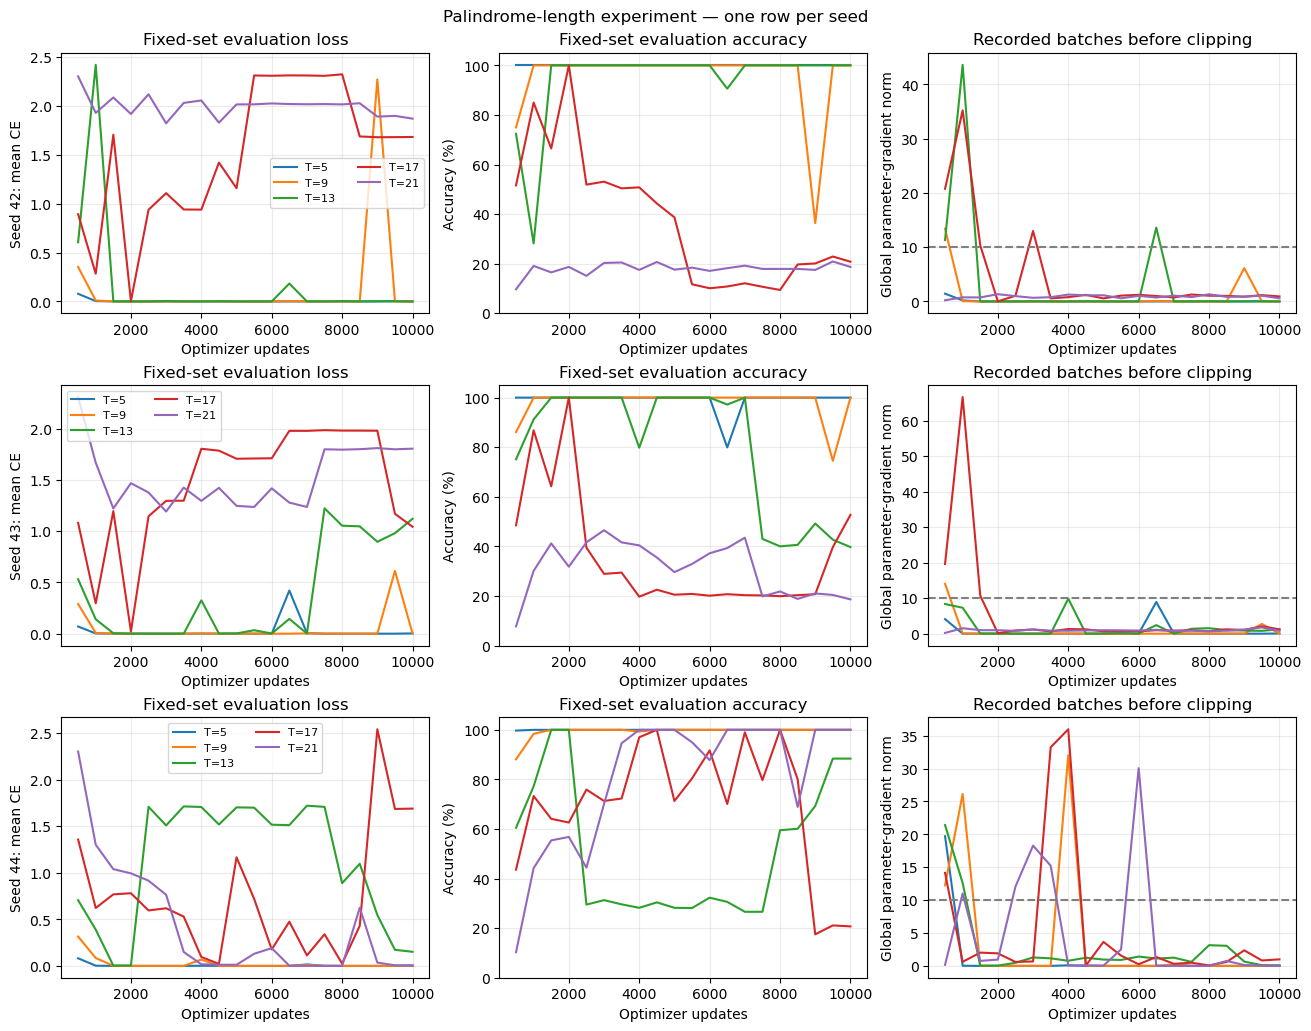

In [6]:
seeds=summary['seeds']
fig, axes = plt.subplots(len(seeds), 3, figsize=(13, 3.4*len(seeds)), squeeze=False, constrained_layout=True)
colors={length:plt.get_cmap('tab10')(i) for i,length in enumerate(lengths)}
for row,seed in enumerate(seeds):
    for record in records:
        if record['seed']!=seed: continue
        saved=json.loads((summary_path.parent/record['history_path']).read_text())
        history=saved['history']; length=record['palindrome_length']; color=colors[length]
        axes[row,0].plot(history['steps'],history['eval_loss'],color=color,label=f'T={length}')
        axes[row,1].plot(history['steps'],100*np.asarray(history['eval_accuracy']),color=color)
        axes[row,2].plot(history['steps'],history['gradient_norm_before_clip'],color=color)
    axes[row,0].set(ylabel=f'Seed {seed}: mean CE',title='Fixed-set evaluation loss')
    axes[row,1].set(ylabel='Accuracy (%)',title='Fixed-set evaluation accuracy',ylim=(0,105))
    axes[row,2].set(ylabel='Global parameter-gradient norm',title='Recorded batches before clipping')
    axes[row,2].axhline(10,color='gray',linestyle='--',label='Clipping threshold')
    axes[row,0].legend(fontsize=8,ncol=2)
    for ax in axes[row]:
        ax.set_xlabel('Optimizer updates'); ax.grid(alpha=0.25)
fig.suptitle(scope+' — one row per seed')
fig.savefig(summary_path.parent/'learning_curves.png',dpi=160)
plt.show()


In [7]:
shortest = int(np.argmin(lengths))
longest = int(np.argmax(lengths))
display(Markdown(
    f"At the recorded budget of **{summary['train_steps']:,} updates**, mean final accuracy is "
    f"**{means[shortest]:.2f}% at T={lengths[shortest]}** and "
    f"**{means[longest]:.2f}% at T={lengths[longest]}**. "
    f"The longest-minus-shortest difference is **{means[longest] - means[shortest]:+.2f} percentage points**."
))
if len(summary["seeds"]) == 1:
    display(Markdown("The study contains one seed. Seed-to-seed variability has not been measured."))


At the recorded budget of **10,000 updates**, mean final accuracy is **100.00% at T=5** and **45.77% at T=21**. The longest-minus-shortest difference is **-54.23 percentage points**.

In [8]:
drops = []
for record in records:
    saved = json.loads((summary_path.parent / record["history_path"]).read_text())
    curve = saved["history"]["eval_accuracy"]
    if len(curve) > 1 and curve[-2] - curve[-1] > 0.1:
        drops.append(f"T={record['palindrome_length']} fell from {curve[-2]:.2%} at the preceding recorded update to {curve[-1]:.2%} at the final update")
if drops:
    display(Markdown("Observed late-training changes: " + "; ".join(drops) +
        ". These trajectories indicate optimization instability at the recorded budget. The final endpoint is retained for the fixed-budget comparison."))
if np.any(np.diff(means) > 0):
    display(Markdown("Final accuracy is nonmonotonic across the sampled lengths. This run does not establish a universal ordering by length."))


Final accuracy is nonmonotonic across the sampled lengths. This run does not establish a universal ordering by length.

## Interpretation and limitations

- Compare final accuracies with the learning trajectories. A low final score can reflect optimization difficulty under the chosen budget as well as difficulty retaining information over longer sequences.
- The global gradient norm is measured over parameters for a few recorded batches. It does not directly measure how gradients decay at each time step, so it cannot by itself establish a vanishing-gradient mechanism.
- Evaluation samples are fixed within a run and independently generated from training draws. At T=5 there are only 1,000 possible palindromes, so repeated sequences and train/evaluation overlap are expected. The score estimates performance on the generating distribution.
- Hyperparameters and update budgets are fixed before the length comparison. Test accuracy is not used for checkpoint selection. More seeds and the full default update budget are needed to characterize robustness of the observed pattern.

## Verification and saved-state recovery

Run `python verify_rnn.py` for recurrence checks, finite-difference gradients for every parameter of a small RNN, evaluation RNG isolation, weighted metrics, and continuous-versus-resumed CPU training equivalence.

Each training run writes its own directory. At every evaluation, atomic `checkpoint.pt` and `history.json` saves preserve progress; the checkpoint is authoritative if interrupted between those writes. A final `model.pt` stores inference weights. Resume with `--resume path/to/checkpoint.pt` and the matching configuration, setting `--train_steps` to the desired total. A new output folder preserves the original run. CPU continuation was tested with identical software and thread settings. Cross-device bitwise identity is unverified.

The sampler uses `num_workers=0`, ignores its index, and generates each example from NumPy. Restoring NumPy state recovers the next sample. Model, RMSProp, CPU PyTorch RNG, history, and update count are also restored. Optional GPU execution has not been verified in this environment.

## Additional diagnostic: gradients through time

`diagnose_rnn.py` replays the exact saved recurrence and verifies its logits against `VanillaRNN.forward`. For 256 fixed diagnostic sequences (seed 20261119), it records the per-example norm of the loss gradient with respect to each hidden state, averaged across examples. The batch-mean loss scaling is explicitly removed. It also measures the fraction of hidden activations with absolute value greater than 0.99.

These gradients are distinct from the global parameter-gradient norm logged during training. They describe sensitivity at a fixed checkpoint. Different models have different losses, so absolute magnitudes should not be interpreted as a pure sequence-length effect. A copy-first-digit oracle checks the task rule; it is not a learned baseline.

| T | Seed | Diagnostic accuracy | Copy-first oracle | First / last hidden-gradient norm |
|---|---|---|---|---|
| 5 | 42 | 100.00% | 100.00% | 2.44 |
| 5 | 43 | 100.00% | 100.00% | 1.42 |
| 5 | 44 | 100.00% | 100.00% | 1.17 |
| 9 | 42 | 100.00% | 100.00% | 1.67 |
| 9 | 43 | 100.00% | 100.00% | 2.41 |
| 9 | 44 | 100.00% | 100.00% | 3.51 |
| 13 | 42 | 100.00% | 100.00% | 4.21 |
| 13 | 43 | 45.31% | 100.00% | 0.00494 |
| 13 | 44 | 91.02% | 100.00% | 0.0119 |
| 17 | 42 | 21.88% | 100.00% | 0 |
| 17 | 43 | 55.86% | 100.00% | 0.0224 |
| 17 | 44 | 20.70% | 100.00% | 8.58e-11 |
| 21 | 42 | 19.53% | 100.00% | 1.3e-12 |
| 21 | 43 | 17.97% | 100.00% | 9.94e-10 |
| 21 | 44 | 100.00% | 100.00% | 2.06 |

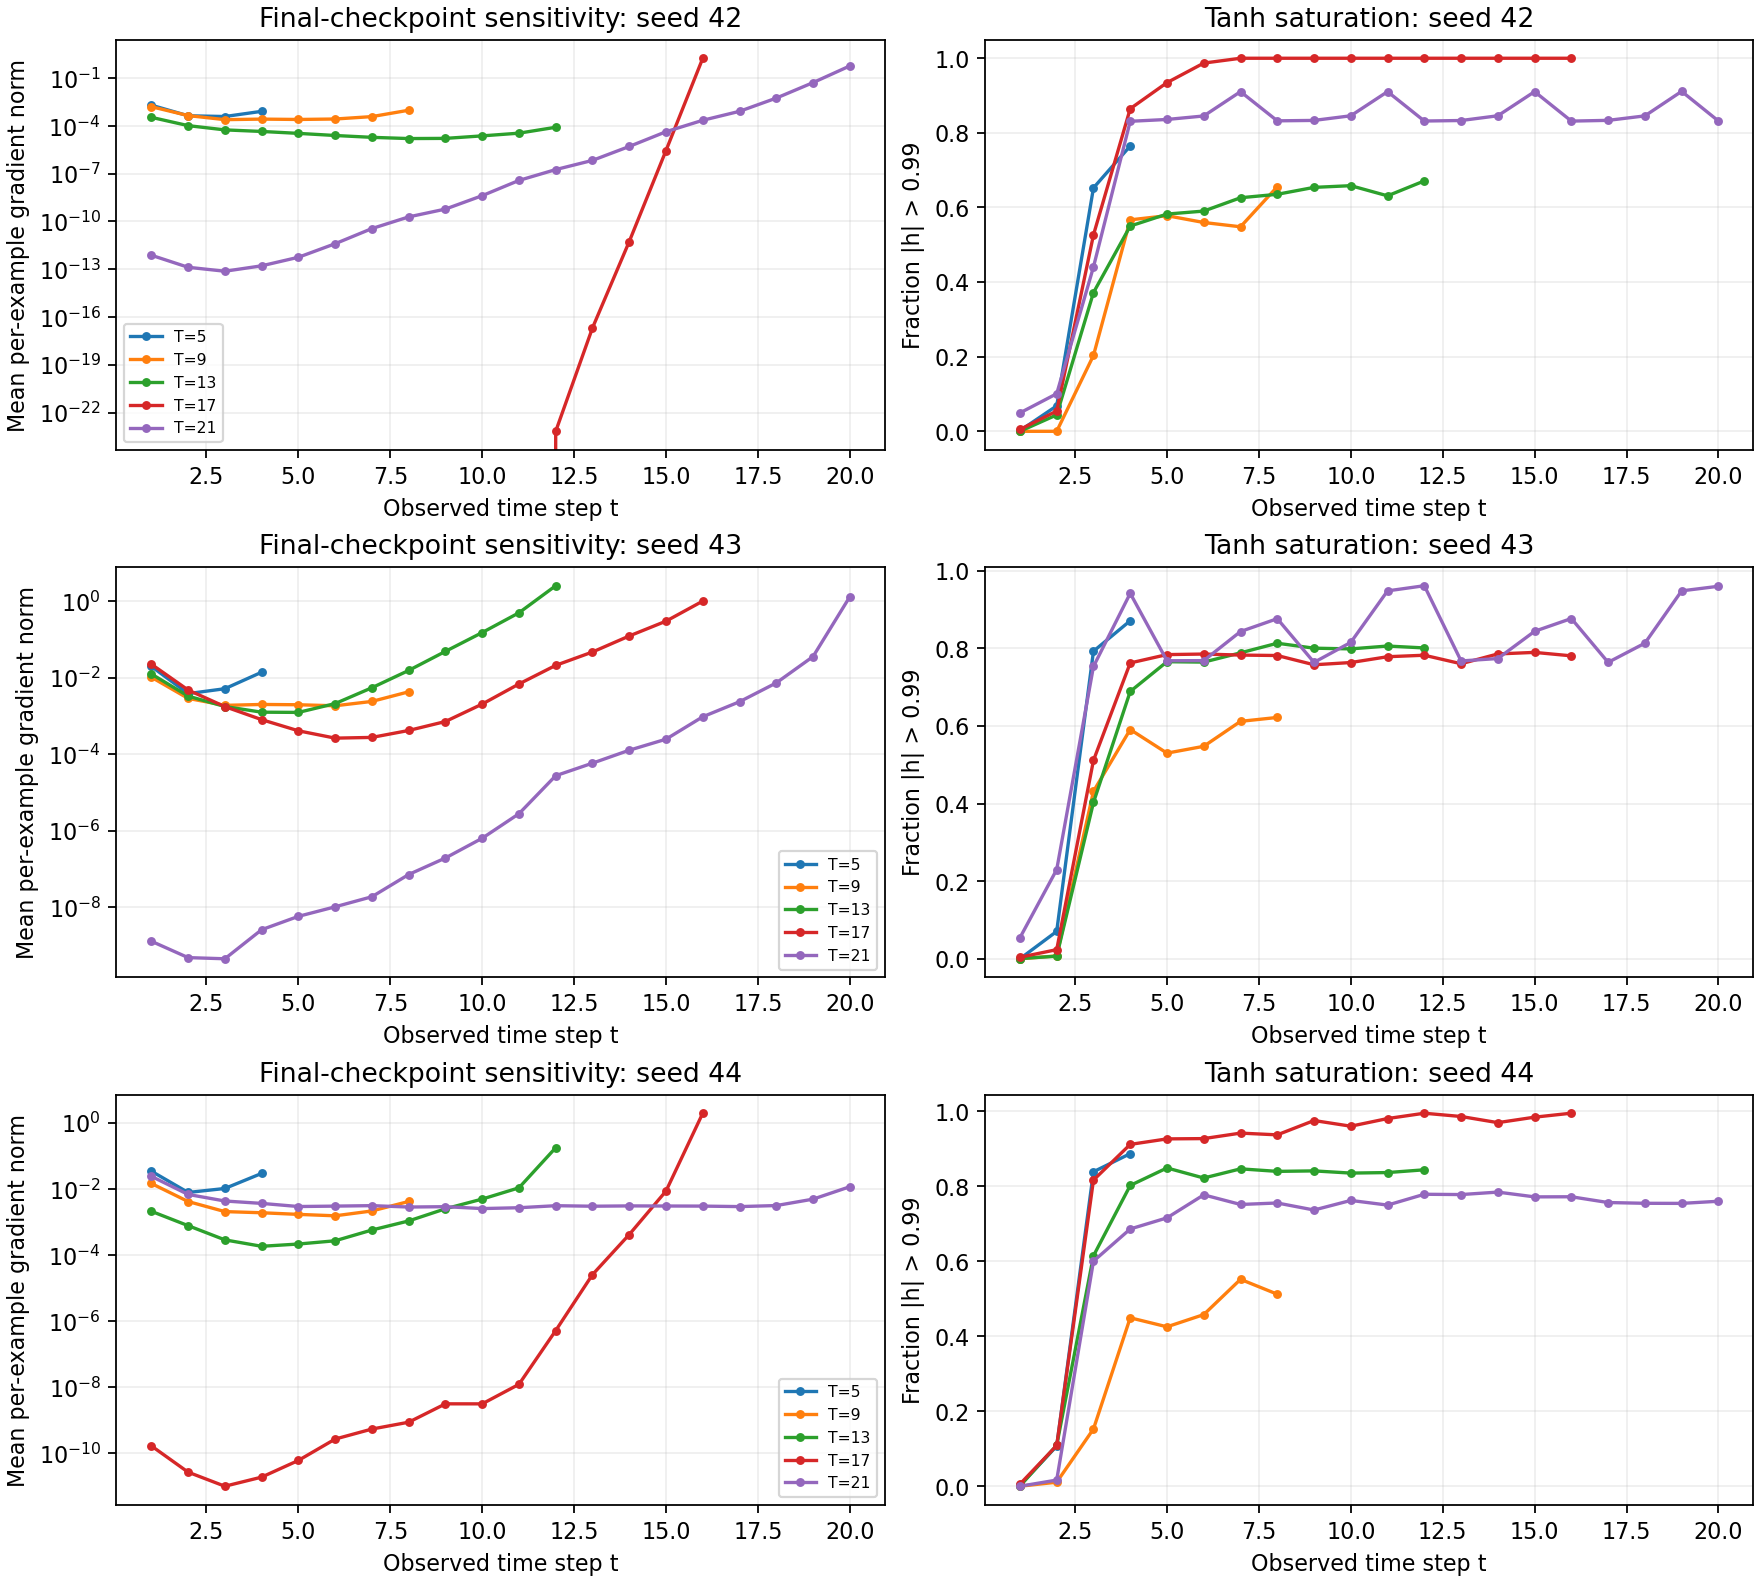

A ratio greater than one indicates a larger gradient norm at the first observed state than at the last for this diagnostic batch. The measurements do not support a blanket claim that every poorly performing checkpoint has a monotonically vanishing gradient. Causal diagnosis requires additional checkpoints and controlled interventions.

In [9]:
from IPython.display import Image
DIAGNOSE = False  # Optional: regenerate diagnostics for the displayed study.
if DIAGNOSE:
    from diagnose_rnn import diagnose
    diagnose(summary_path.parent)
diagnostic_path=summary_path.parent/'diagnostics.json'
if diagnostic_path.exists():
    diagnostic=json.loads(diagnostic_path.read_text())
    rows=['| T | Seed | Diagnostic accuracy | Copy-first oracle | First / last hidden-gradient norm |', '|---|---|---|---|---|']
    for r in diagnostic['records']:
        norms=r['mean_per_example_hidden_gradient_norm']
        rows.append(f"| {r['total_length']} | {r['seed']} | {r['diagnostic_accuracy']:.2%} | {r['oracle_accuracy']:.2%} | {norms[0]/norms[-1]:.3g} |")
    display(Markdown('\n'.join(rows)))
    display(Image(filename=str(summary_path.parent/'temporal_diagnostics.png')))
    display(Markdown('A ratio greater than one indicates a larger gradient norm at the first observed state than at the last for this diagnostic batch. The measurements do not support a blanket claim that every poorly performing checkpoint has a monotonically vanishing gradient. Causal diagnosis requires additional checkpoints and controlled interventions.'))
else:
    print('Temporal diagnostics have not been generated for this study.')

## Even-length coverage

Two supplementary runs use T=6 and T=10, seed 42, and the same 10,000-update budget. They verify that the training pipeline handles even-length palindromes. A single seed at these lengths does not isolate an odd/even parity effect.

In [10]:
even_path = PART_DIR / 'results/rnn_even_lengths/study-eigpmkd2/summary.json'
even_summary=json.loads(even_path.read_text())
assert even_summary['status']=='complete'
for record in even_summary['records']:
    print(f"T={record['palindrome_length']}, seed={record['seed']}, updates={record['train_steps']}, final accuracy={record['final_eval_accuracy']:.2%}")

T=6, seed=42, updates=10000, final accuracy=100.00%
T=10, seed=42, updates=10000, final accuracy=90.90%


## Interpreting the formal temporal diagnostics

At 10,000 updates, T=21/seed42 has a first-to-last hidden-gradient norm ratio of approximately 1.30e-12, while the successful T=21/seed44 checkpoint has a ratio of 2.06. This supports strong early-state sensitivity attenuation at some unsuccessful final checkpoints. The T=17/seed42 first norm is numerically zero in the float32 norm calculation; zero is not displayed on a logarithmic axis and is not proof of an exactly zero real-valued derivative.

The saved 1,000-update pilot offers a different failure case: T=13/seed42 has a ratio around 44.7 despite poor diagnostic accuracy. Distinguish training stages and loss scales before assigning a common mechanism to every failure. These are checkpoint-local measurements on a separate 256-example diagnostic batch, not replacements for the main 1,000-example evaluation metrics.